# 01 — Raw Data Exploration

Runs the raw-data audit (`src/check_raw_data.py`) and previews all 7 raw rasters before any
alignment/preprocessing happens. `check_raw_data.py`'s own assertions are the actual audit
gate for the pipeline (see `outputs/tables/raw_data_audit.csv`) — this notebook is for
eyeballing the rasters and sanity-checking that gate's numbers visually.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

import numpy as np
import matplotlib.pyplot as plt
import rasterio

import check_raw_data as crd

plt.rcParams["figure.dpi"] = 100

## Run the audit gate

In [2]:
exit_code = crd.main()
print("\ncheck_raw_data exit code:", exit_code, "(0 = all checks passed)")

2026-07-04 20:12:49,756 | INFO    | colombo-uhi | 
colombo_lst_2024_dry_season.tif


2026-07-04 20:12:49,758 | INFO    | colombo-uhi |   crs=EPSG:4326 res=(0.000269, 0.000269) shape=269x448 valid%=100.0


2026-07-04 20:12:49,758 | INFO    | colombo-uhi |   min=28.553 max=49.284 mean=36.123 std=5.803


2026-07-04 20:12:49,759 | INFO    | colombo-uhi |   [PASS] lst: not entirely nodata/constant: valid%=100.0, min=28.55346152000004, max=49.28375282000002


2026-07-04 20:12:49,759 | INFO    | colombo-uhi |   [PASS] lst: plausible Celsius range (20-55): min=28.55 max=49.28


2026-07-04 20:12:49,759 | INFO    | colombo-uhi |   [PASS] lst: CRS is EPSG:4326: crs=EPSG:4326


... (37 outputs left out)

2026-07-04 20:12:49,964 | INFO    | colombo-uhi | 
Wrote D:\Campus work\Projects and practicals\Urban computing\colombo-uhi\outputs\tables\raw_data_audit.csv


2026-07-04 20:12:49,965 | INFO    | colombo-uhi | ============================================================


2026-07-04 20:12:49,965 | INFO    | colombo-uhi | RAW DATA AUDIT: ALL CHECKS PASSED



check_raw_data exit code: 0 (0 = all checks passed)


## The 7 raw layers

| Layer | Source | Role |
|---|---|---|
| LST | Landsat 8/9 C2 L2 thermal band, dry-season composite | Main temperature layer — everything else explains or is explained by this. |
| NDVI | Landsat, same composite | Vegetation greenness; `1-NDVI` is one of the 3 HEI components. |
| NDBI | Landsat, same composite | Built-up index; used for correlation checks, not the HEI formula itself. |
| WorldCover | ESA WorldCover v200, 2021 | Categorical land cover — source of `land_mask` (class 80 = water). |
| WorldPop | WorldPop 2020, ~100m | Population count per cell — source of `pop_density`, the 2nd HEI component. |
| GHSL built-surface | JRC GHSL 2020 | Built-up surface area (m²/cell) — validation covariate, not in the HEI formula. |
| MODIS LST | MOD11A2, 1km | Coarse LST, used only as a pattern-consistency check against Landsat LST in `validation.py`. |

Below: CRS/shape/valid%% + summary stats (from `check_raw_data.read_stats`, not re-derived
here) and a quick-look plot of each raw raster, straight off `data/raw/` — before any
reprojection, resampling, or masking.

### LST (`colombo_lst_2024_dry_season.tif`)
Landsat thermal, already converted to Celsius at export time.

CRS=EPSG:4326  shape=269x448  valid%=100.0
min=28.553  max=49.284  mean=36.123  std=5.803


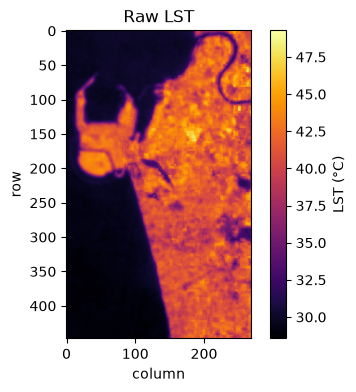

In [3]:
path = ROOT / "data/raw/colombo_lst_2024_dry_season.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="inferno")
plt.colorbar(label="LST (°C)")
plt.title("Raw LST")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

### NDVI (`colombo_ndvi_2024_dry_season.tif`)
Vegetation index, range [-1, 1].

CRS=EPSG:4326  shape=269x448  valid%=78.36
min=-0.999  max=0.990  mean=0.128  std=0.428


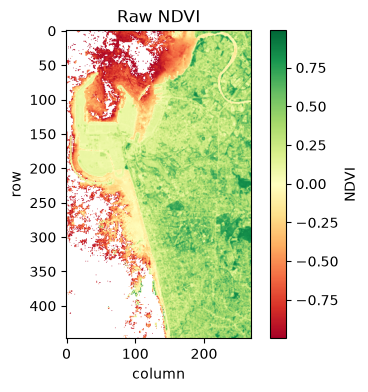

In [4]:
path = ROOT / "data/raw/colombo_ndvi_2024_dry_season.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="RdYlGn")
plt.colorbar(label="NDVI")
plt.title("Raw NDVI")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

### NDBI (`colombo_ndbi_2024_dry_season.tif`)
Built-up index, range [-1, 1].

CRS=EPSG:4326  shape=269x448  valid%=78.45
min=-0.689  max=0.999  mean=0.137  std=0.301


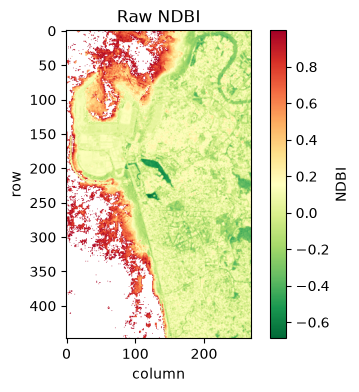

In [5]:
path = ROOT / "data/raw/colombo_ndbi_2024_dry_season.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="RdYlGn_r")
plt.colorbar(label="NDBI")
plt.title("Raw NDBI")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

### WorldCover (`colombo_worldcover_2021.tif`)
Categorical ESA land-cover codes, native ~10m (needs mode-aggregation to 100m in `preprocess.py`) — values are discrete codes (10=tree, 20=shrub, 30=grass, 40=crop, 50=built-up, 60=bare, 80=water, 90=wetland, ...), *not* a continuous scale, hence the qualitative colormap below.

CRS=EPSG:4326  shape=804x1340  valid%=100.0
min=10.000  max=90.000  mean=60.510  std=20.975


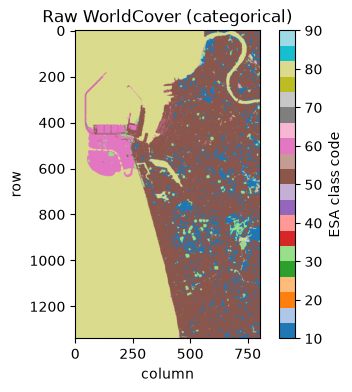

In [6]:
path = ROOT / "data/raw/colombo_worldcover_2021.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="tab20")
plt.colorbar(label="ESA class code")
plt.title("Raw WorldCover (categorical)")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

### WorldPop (`colombo_worldpop_2020.tif`)
Population **count** per ~100m cell (not a density) — the raw nodata you'll see below is almost entirely ocean/lagoon, not zero-population land.

CRS=EPSG:4326  shape=81x135  valid%=54.57
min=1.244  max=518.799  mean=97.407  std=75.125


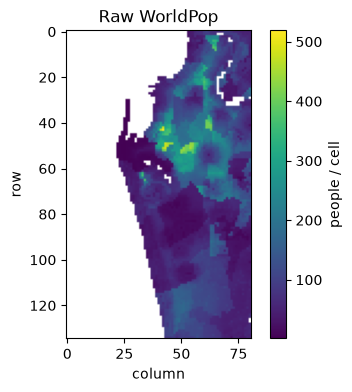

In [7]:
path = ROOT / "data/raw/colombo_worldpop_2020.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="viridis")
plt.colorbar(label="people / cell")
plt.title("Raw WorldPop")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

### GHSL built-surface (`colombo_ghsl_built_2020.tif`)
Built-up surface area in m² per cell. The only raw layer natively in a different CRS (ESRI:54009 Mollweide) — this raw preview is still in its native CRS/grid, so its orientation/shape looks different from the others.

CRS=ESRI:54009  shape=85x149  valid%=100.0
min=0.000  max=8130.000  mean=1768.477  std=2202.226


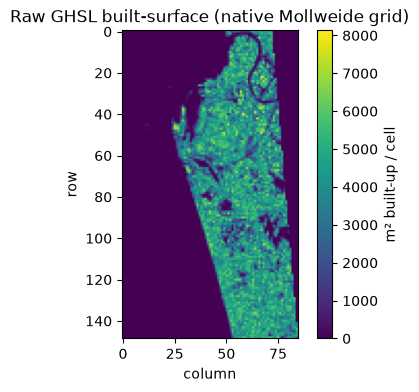

In [8]:
path = ROOT / "data/raw/colombo_ghsl_built_2020.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="viridis")
plt.colorbar(label="m² built-up / cell")
plt.title("Raw GHSL built-surface (native Mollweide grid)")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

### MODIS LST (`colombo_modis_lst_2024_dry_season.tif`)
1km resolution, only ~51% valid over this small AOI (9x15 pixel grid total) — used later only as a coarse pattern check, never pixel-level ground truth.

CRS=EPSG:4326  shape=9x15  valid%=51.11
min=31.798  max=35.535  mean=33.794  std=0.937


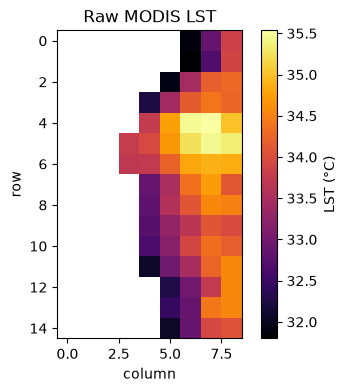

In [9]:
path = ROOT / "data/raw/colombo_modis_lst_2024_dry_season.tif"
stats = crd.read_stats(path)
print(f"CRS={stats['crs']}  shape={stats['width']}x{stats['height']}  valid%={stats['valid_percent']}")
print(f"min={stats['min']:.3f}  max={stats['max']:.3f}  mean={stats['mean']:.3f}  std={stats['std']:.3f}")

with rasterio.open(path) as src:
    arr = src.read(1).astype("float64")
    nodata = src.nodata
if nodata is not None:
    arr = np.where(arr == nodata, np.nan, arr)

plt.figure(figsize=(5, 4))
plt.imshow(arr, cmap="inferno")
plt.colorbar(label="LST (°C)")
plt.title("Raw MODIS LST")
plt.xlabel("column")
plt.ylabel("row")
plt.show()

## Takeaways

- All 7 rasters open cleanly and pass every check in `check_raw_data.py` (see the audit output
  above and `outputs/tables/raw_data_audit.csv`).
- LST and MODIS LST are both already in Celsius (no Kelvin/DN conversion needed downstream).
- WorldCover and GHSL need special handling in `preprocess.py`: WorldCover because it's
  categorical and 10x finer than the target grid, GHSL because it's in a different CRS entirely.
- None of the 7 rasters carry a GDAL nodata tag (bare NaN) — `preprocess.py` sets nodata
  explicitly in every aligned output rather than relying on the source files' metadata.